In [2]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
import re

In [3]:

# print("-- First 150k --\n")
# df_kaggle = pd.read_csv("../dataset/raw/Kaggle/winemag-data_first150k.csv")
# print(df_kaggle.shape)
# print(df_kaggle.columns)


# print("\n-- v2 130k --\n")
# df_kaggle_v2 = pd.read_csv("../dataset/raw/Kaggle/winemag-data-130k-v2.csv")  # extra 'taster_name','taster_twitter_handle','title'
# print(df_kaggle_v2.shape)
# print(df_kaggle_v2.columns)

# common = df_kaggle.columns.intersection(df_kaggle_v2.columns) #give you common columns between df_kaggle and df_kaggle_v2
# print(list(common))

# df = pd.concat([df_kaggle[common],df_kaggle_v2[common]], ignore_index=True) #merge
# print(df.info())
# print(df.describe())

df = pd.read_csv("../dataset/raw/Kaggle/winemag-data-130k-v2.csv")

In [4]:
#info about data
print(df.shape)

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "full": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
summary

(129971, 14)


,dtype,full,missing,missing_%,unique
Unnamed: 0,int64,129971,0,0.00,129971
country,str,129908,63,0.05,43
description,str,129971,0,0.00,119955
designation,str,92506,37465,28.83,37979
points,int64,129971,0,0.00,21
price,float64,120975,8996,6.92,390
province,str,129908,63,0.05,425
region_1,str,108724,21247,16.35,1229
region_2,str,50511,79460,61.14,17
taster_name,str,103727,26244,20.19,19


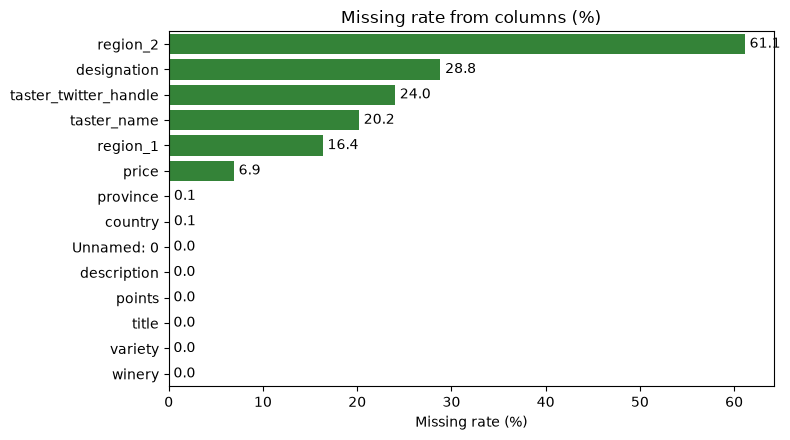

In [5]:
# visualazing missing value

missing = summary.sort_values("missing_%", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=missing["missing_%"], y=missing.index, ax=ax, color="#27902c")
ax.set_title("Missing rate from columns (%)")
ax.set_xlabel("Missing rate (%)"); ax.set_ylabel("")
for i, v in enumerate(missing["missing_%"]):
    ax.text(v + 0.5, i, f"{v:.1f}", va="center")
plt.tight_layout(); plt.show()

In [6]:
#statistic of numeric columns
df[["points","price"]].describe().T

,count,mean,std,min,25%,50%,75%,max
points,129971.0,88.447138,3.039730,80.0,86.0,88.0,91.0,100.0
price,120975.0,35.363389,41.022218,4.0,17.0,25.0,42.0,3300.0


In [7]:
#giving duplicated rows
print(
f"same row number: ", df.duplicated().sum(),
f"\nsame description number: ",df.duplicated(subset=["description"]).sum(),
f"\nsame title number: ",df.duplicated(subset=["Unnamed: 0"]).sum(),
)



same row number:  0 
same description number:  10016 
same title number:  0


In [8]:
#Robson & Amadhl_Culleton_Table2 
rows = []
for col in ['Unnamed: 0', 'country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery']:
    vc = df[col].value_counts()
    rows.append({"sütun": col, "labeled_row": int(vc.sum()), "unlabeled_row": int(df[col].isna().sum()),
                 "attribute_num": len(vc), "mean_attribute_shape": round(vc.mean(), 1),
                 "median": vc.median(), "max": vc.max(), "min": vc.min()})
pd.DataFrame(rows).set_index("sütun")

,labeled_row,unlabeled_row,attribute_num,mean_attribute_shape,median,max,min
sütun,,,,,,,
Unnamed: 0,129971,0,129971,1.0,1.0,1,1
country,129908,63,43,3021.1,86.0,54504,1
description,129971,0,119955,1.1,1.0,3,1
designation,92506,37465,37979,2.4,1.0,2009,1
points,129971,0,21,6189.1,3758.0,17207,19
price,120975,8996,390,310.2,4.0,6940,1
province,129908,63,425,305.7,12.0,36247,1
region_1,108724,21247,1229,88.5,11.0,4480,1
region_2,50511,79460,17,2971.2,1169.0,11065,231


In [9]:
# add description features 
df["desc_chars"] = df["description"].str.len()
df["desc_word"] = df["description"].str.split().str.len()
df[["desc_chars","desc_word"]].describe().T

,count,mean,std,min,25%,50%,75%,max
desc_chars,129971.0,242.601065,66.584276,20.0,197.0,237.0,282.0,829.0
desc_word,129971.0,40.379615,11.111982,3.0,33.0,39.0,47.0,135.0


In [10]:
# show us to text with features
for _, r in df.sample(3, random_state=1).iterrows():
    print(f"[{r['points']} points | {r['country']} | {r['variety']} | ${r['price']}]")
    print(r["description"], "\n")

[90 points | Portugal | Portuguese Red | $20.0]
This latest vintage of Falcoaria red is smooth and ripe while also structured. It has great tannins, a dense texture and layers of rich red fruits and acidity. The wood aging gives extra richness as well as spicing up the fruitiness. Drink from 2016. 

[87 points | US | Cabernet Sauvignon | $13.0]
This is a good, solidly made wine with medium body and a pleasant mix of spicy oak and juicy fruit flavors. The texture goes easy on the palate. 

[87 points | New Zealand | Sauvignon Blanc | $16.0]
This fruit-forward Sauvignon Blanc offers a blend of pineapple and nectarine up front, then shows a stony, austere side on the palate, where it ends on dry notes of crushed stone. 



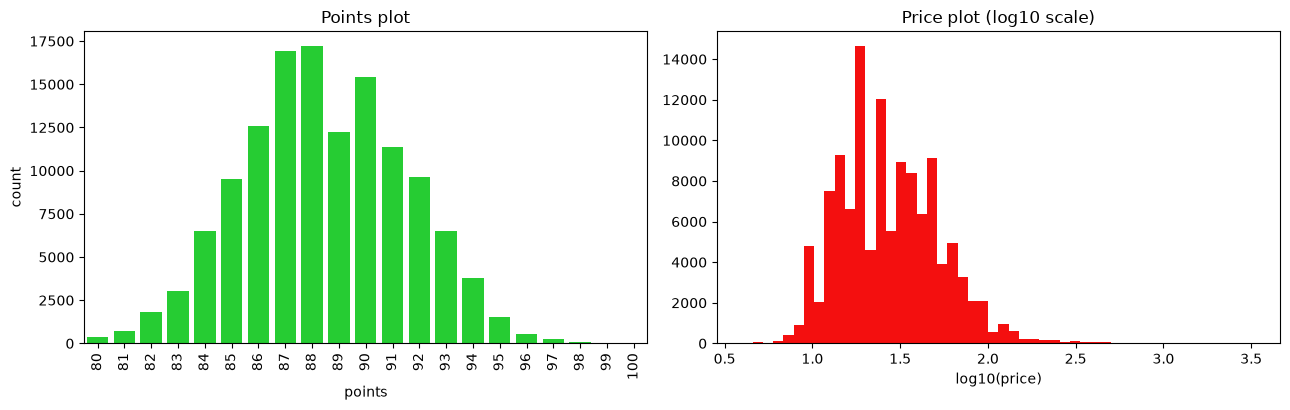

Points: mean=88.45, median=88.0
Price: mean=35.36, median=25.0, min=4.0, max=3300.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.countplot(x="points", data=df, ax=axes[0], color="#0ae81c")
axes[0].set_title("Points plot")
axes[0].tick_params(axis="x", rotation=90)

p = df["price"].dropna()
axes[1].hist(np.log10(p), bins=50, color="#f40f0f")
axes[1].set_title("Price plot (log10 scale)")
axes[1].set_xlabel("log10(price)")
plt.tight_layout(); plt.show()

print(f"Points: mean={df.points.mean():.2f}, median={df.points.median()}")
print(f"Price: mean={p.mean():.2f}, median={p.median()}, min={p.min()}, max={p.max()}")

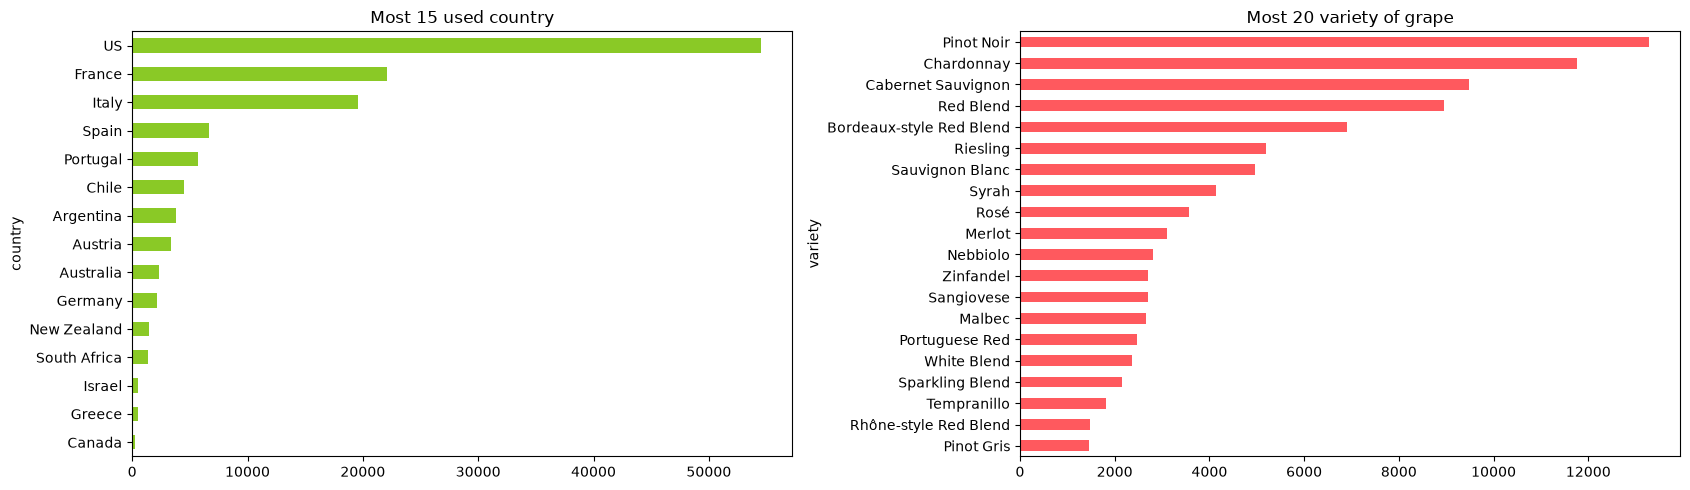

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

df["country"].value_counts().head(15).sort_values().plot.barh(ax=axes[0], color="#8ac926")
axes[0].set_title("Most 15 used country")

df["variety"].value_counts().head(20).sort_values().plot.barh(ax=axes[1], color="#ff595e")
axes[1].set_title("Most 20 variety of grape")

plt.tight_layout(); plt.show()

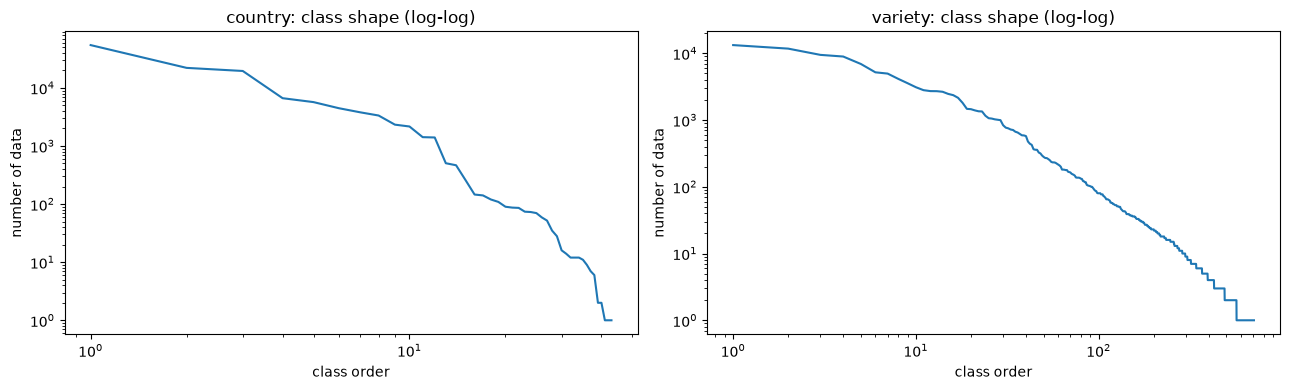

In [13]:
# Class unbalanced : long tail – country and variety
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["country", "variety"]):
    vc = df[col].value_counts()
    ax.plot(range(1, len(vc) + 1), vc.values)
    ax.set_yscale("log"); ax.set_xscale("log")
    ax.set_title(f"{col}: class shape (log-log)")
    ax.set_xlabel("class order"); ax.set_ylabel("number of data")
plt.tight_layout(); plt.show()

In [14]:
# drop duplicated rows
df = df.drop(columns=["desc_chars", "desc_word"]).copy()
n0 = len(df)

df = df.drop_duplicates()
n1 = len(df)
df = df.drop_duplicates(subset=["description"])
n2 = len(df)
print(f"Beginning: {n0:,} | after full repeat: {n1:,} | after some comment: {n2:,}")
print(f"Sum of deleted duplicated rows: {n0 - n2:,}")

# delete non useful useful columns
drop_cols = ["Unnamed: 0","taster_twitter_handle", "region_1", "region_2", "designation", "winery", "title"]
df = df.drop(columns=drop_cols).reset_index(drop=True)
df.columns.tolist()

Beginning: 129,971 | after full repeat: 129,971 | after some comment: 119,955
Sum of deleted duplicated rows: 10,016


['country',
 'description',
 'points',
 'price',
 'province',
 'taster_name',
 'variety']

In [15]:
# clean text
def clean_text(t: str) -> str:
    t = t.lower()
    t = re.sub(r"[^a-z\u00e0-\u00ff\s]", " ", t)   # only alphabetic characters
    return re.sub(r"\s+", " ", t).strip()

df["desc_clean"] = df["description"].map(clean_text)
df["n_words"] = df["desc_clean"].str.split().str.len()

# categorical missing
df["taster_name"] = df["taster_name"].fillna("Unknown")
print("any empty desc?:", (df["desc_clean"].str.len() == 0).sum())
df[["description", "desc_clean"]].head(3)

any empty desc?: 0


,description,desc_clean
0,"Aromas include tropical fruit, broom, brimston...",aromas include tropical fruit broom brimstone ...
1,"This is ripe and fruity, a wine that is smooth...",this is ripe and fruity a wine that is smooth ...
2,"Tart and snappy, the flavors of lime flesh and...",tart and snappy the flavors of lime flesh and ...


In [18]:
# target variables 
# 1) points -> 4 class (decrease unbalanced); original points regression was still same
df["points_class"] = pd.cut(df["points"], bins=[79, 84, 89, 94, 100],
                            labels=["80-84", "85-89", "90-94", "95-100"])
# 2) log price
df["log_price"] = np.log1p(df["price"])
df["price_missing"] = df["price"].isna().astype(int)

# 3) Kim (2022) subset : most commented 12 country, 26 variety, 12 commenter_name  + rows with price
top_countries = df["country"].value_counts().head(12).index
top_varieties = df["variety"].value_counts().head(26).index
top_tasters = df["taster_name"].drop(df.index[df.taster_name == "Unknown"]).value_counts().head(12).index
df["in_kim_subset"] = (df["country"].isin(top_countries) & df["variety"].isin(top_varieties)
                       & df["taster_name"].isin(top_tasters) & df["price"].notna())
print("Number rows of Kim subset:", df["in_kim_subset"].sum(), "(in article 73,708)")
df["points_class"].value_counts().sort_index()

Number rows of Kim subset: 67217 (in article 73,708)


points_class
80-84     12085
85-89     62291
90-94     43188
95-100     2391
Name: count, dtype: int64